# Checkpoint 5 - 2º Semestre
## Machine Learning & Modelling + Statistical Computing with R & Python

**Aluno:** Gustavo Santin  
**RM:** 573213

Este notebook realiza a análise exploratória solicitada e a clusterização K-means do dataset Wine. O arquivo `wines.csv` deve ficar na mesma pasta do notebook.

## 1. Importação das bibliotecas e leitura dos dados

O dataset contém 178 vinhos e 13 variáveis quantitativas, além da coluna `Wine`, que representa a classe original. Para o K-means, essa classe será removida porque o objetivo é formar grupos sem usar o rótulo conhecido.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

df = pd.read_csv('wines.csv')
print('Dimensão:', df.shape)
display(df.head())
display(df.describe().T)

Dimensão: (178, 14)


,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,1,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,1,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,1,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,count,mean,std,min,25%,50%,75%,max
Wine,178.0,1.938202,0.775035,1.00,1.0000,2.000,3.0000,3.00
Alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
Malic.acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
Ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
Acl,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
Mg,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
Phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
Flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
Nonflavanoid.phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
Proanth,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58


# PARTE 1 - Statistical Computing with R & Python

Foram escolhidas duas variáveis quantitativas: **Alcohol** (teor alcoólico) e **Malic.acid** (ácido málico).

## 2. Visualização dos dados - Alcohol

A tabela de frequência usa 9 classes de mesma largura. A frequência relativa permite interpretar a probabilidade empírica de um valor cair em cada intervalo.

,Intervalo,fi,fr (%),Fi,Fr acum. (%)
0,"(11.025, 11.452]",3,1.69,3,1.69
1,"(11.452, 11.874]",15,8.43,18,10.11
2,"(11.874, 12.297]",23,12.92,41,23.03
3,"(12.297, 12.719]",28,15.73,69,38.76
4,"(12.719, 13.141]",28,15.73,97,54.49
5,"(13.141, 13.563]",30,16.85,127,71.35
6,"(13.563, 13.986]",29,16.29,156,87.64
7,"(13.986, 14.408]",20,11.24,176,98.88
8,"(14.408, 14.83]",2,1.12,178,100.00


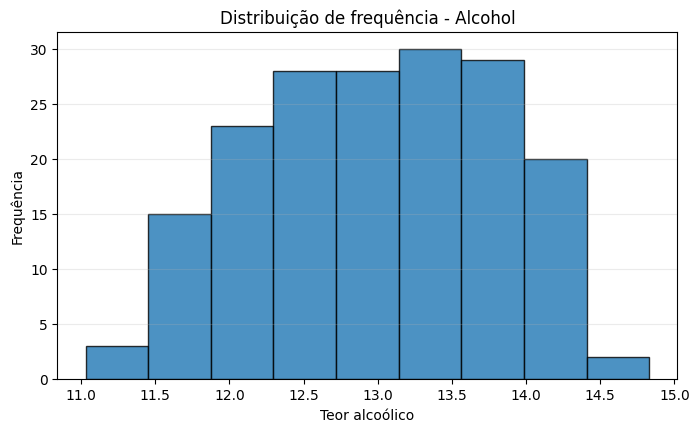

In [2]:
def tabela_frequencia(serie, k=9):
    classes = pd.cut(serie, bins=k, include_lowest=True)
    fi = classes.value_counts(sort=False)
    fr = fi / len(serie)
    return pd.DataFrame({
        'Intervalo': [str(x) for x in fi.index],
        'fi': fi.values,
        'fr (%)': (fr.values * 100).round(2),
        'Fi': fi.cumsum().values,
        'Fr acum. (%)': (fr.cumsum().values * 100).round(2)
    })

freq_alcohol = tabela_frequencia(df['Alcohol'])
display(freq_alcohol)

plt.figure(figsize=(8,4.5))
plt.hist(df['Alcohol'], bins=9, edgecolor='black', alpha=.8)
plt.title('Distribuição de frequência - Alcohol')
plt.xlabel('Teor alcoólico')
plt.ylabel('Frequência')
plt.grid(axis='y', alpha=.25)
plt.show()

# Interpretação: a distribuição é relativamente concentrada em torno de 13,
# com amplitude moderada entre os menores e maiores teores alcoólicos.

## 3. Análise descritiva - Alcohol

In [3]:
def resumo_descritivo(serie):
    return pd.Series({
        'N': serie.count(),
        'Média': serie.mean(),
        'Mediana': serie.median(),
        'Moda': ', '.join(map(lambda x: f'{x:.2f}', serie.mode().tolist())),
        'Mínimo': serie.min(),
        'Máximo': serie.max(),
        'Amplitude': serie.max() - serie.min(),
        'Variância amostral': serie.var(ddof=1),
        'Desvio-padrão amostral': serie.std(ddof=1),
        'Coeficiente de variação (%)': serie.std(ddof=1)/serie.mean()*100,
        'Q1': serie.quantile(.25),
        'Q2': serie.quantile(.50),
        'Q3': serie.quantile(.75),
        'Amplitude interquartil': serie.quantile(.75)-serie.quantile(.25)
    })

display(resumo_descritivo(df['Alcohol']).to_frame('Alcohol'))

# Interpretação: média e mediana são muito próximas, indicando centro em torno de 13.
# O coeficiente de variação é baixo, então Alcohol apresenta dispersão relativa pequena.

,Alcohol
N,178
Média,13.000618
Mediana,13.05
Moda,"12.37, 13.05"
Mínimo,11.03
Máximo,14.83
Amplitude,3.8
Variância amostral,0.659062
Desvio-padrão amostral,0.811827
Coeficiente de variação (%),6.244523


## 4. Análise probabilística - Alcohol

Foi utilizada a **distribuição empírica**, em que a probabilidade é a proporção observada no próprio conjunto de dados.

In [4]:
p1 = (df['Alcohol'] > 13).mean()
p2 = ((df['Alcohol'] >= 12) & (df['Alcohol'] <= 14)).mean()
print(f'P(Alcohol > 13) = {p1:.4f} = {p1*100:.2f}%')
print(f'P(12 <= Alcohol <= 14) = {p2:.4f} = {p2*100:.2f}%')

# Interpretação: as probabilidades acima representam frequências relativas observadas
# entre os 178 vinhos, sem assumir uma distribuição teórica específica.

P(Alcohol > 13) = 0.5169 = 51.69%
P(12 <= Alcohol <= 14) = 0.7697 = 76.97%


## 5. Visualização dos dados - Malic.acid

,Intervalo,fi,fr (%),Fi,Fr acum. (%)
0,"(0.734, 1.302]",21,11.80,21,11.80
1,"(1.302, 1.864]",68,38.20,89,50.00
2,"(1.864, 2.427]",25,14.04,114,64.04
3,"(2.427, 2.989]",16,8.99,130,73.03
4,"(2.989, 3.551]",16,8.99,146,82.02
5,"(3.551, 4.113]",17,9.55,163,91.57
6,"(4.113, 4.676]",8,4.49,171,96.07
7,"(4.676, 5.238]",4,2.25,175,98.31
8,"(5.238, 5.8]",3,1.69,178,100.00


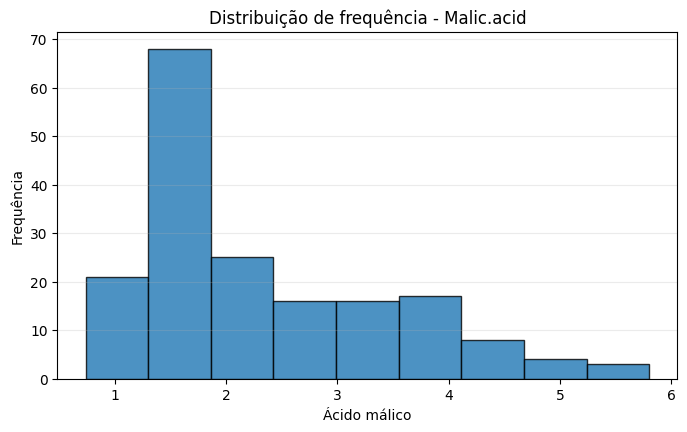

In [5]:
freq_malic = tabela_frequencia(df['Malic.acid'])
display(freq_malic)

plt.figure(figsize=(8,4.5))
plt.hist(df['Malic.acid'], bins=9, edgecolor='black', alpha=.8)
plt.title('Distribuição de frequência - Malic.acid')
plt.xlabel('Ácido málico')
plt.ylabel('Frequência')
plt.grid(axis='y', alpha=.25)
plt.show()

# Interpretação: Malic.acid apresenta maior assimetria à direita do que Alcohol,
# com vários vinhos concentrados em valores baixos e uma cauda de valores altos.

## 6. Análise descritiva - Malic.acid

In [6]:
display(resumo_descritivo(df['Malic.acid']).to_frame('Malic.acid'))

# Interpretação: a média é maior que a mediana e o coeficiente de variação é elevado,
# mostrando maior heterogeneidade e assimetria nos valores de ácido málico.

,Malic.acid
N,178
Média,2.336348
Mediana,1.865
Moda,1.73
Mínimo,0.74
Máximo,5.8
Amplitude,5.06
Variância amostral,1.248015
Desvio-padrão amostral,1.117146
Coeficiente de variação (%),47.815905


## 7. Análise probabilística - Malic.acid

In [7]:
p3 = (df['Malic.acid'] > 3).mean()
p4 = ((df['Malic.acid'] >= 1) & (df['Malic.acid'] <= 2.5)).mean()
print(f'P(Malic.acid > 3) = {p3:.4f} = {p3*100:.2f}%')
print(f'P(1 <= Malic.acid <= 2.5) = {p4:.4f} = {p4*100:.2f}%')

# Interpretação: novamente, as probabilidades são empíricas e correspondem
# diretamente às proporções observadas no conjunto de dados.

P(Malic.acid > 3) = 0.2640 = 26.40%
P(1 <= Malic.acid <= 2.5) = 0.6124 = 61.24%


# PARTE 2 - Machine Learning & Modelling

## 8. Introdução

O problema é agrupar vinhos com características químicas semelhantes sem utilizar previamente a classe original. A solução proposta é o algoritmo **K-means**, aplicado após padronização das variáveis para impedir que atributos em escalas maiores, como `Proline` e `Mg`, dominem as distâncias.

## 9. Pré-processamento

In [8]:
print('Valores nulos por coluna:')
display(df.isna().sum().to_frame('nulos'))

# Wine é o rótulo original e não deve participar da clusterização não supervisionada.
X = df.drop(columns=['Wine'])

# Padronização: cada variável fica com média aproximadamente 0 e desvio-padrão 1.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Formato após pré-processamento:', X_scaled.shape)

Valores nulos por coluna:


,nulos
Wine,0
Alcohol,0
Malic.acid,0
Ash,0
Acl,0
Mg,0
Phenols,0
Flavanoids,0
Nonflavanoid.phenols,0
Proanth,0


Formato após pré-processamento: (178, 13)


## 10. Escolha do número ideal de grupos - Elbow e Silhouette Score

,k,Inércia,Silhouette Score
0,2,1658.7589,0.2593
1,3,1277.9285,0.2849
2,4,1175.3519,0.2586
3,5,1107.0073,0.2315
4,6,1046.0023,0.2372
5,7,981.5952,0.2036
6,8,935.2012,0.1570
7,9,889.8929,0.1499
8,10,845.8952,0.1436


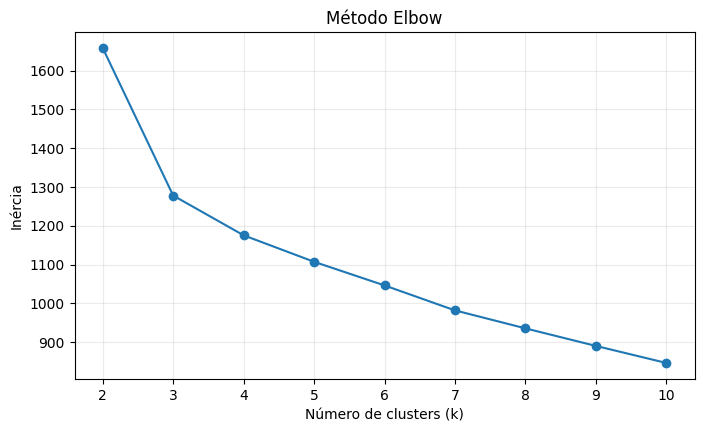

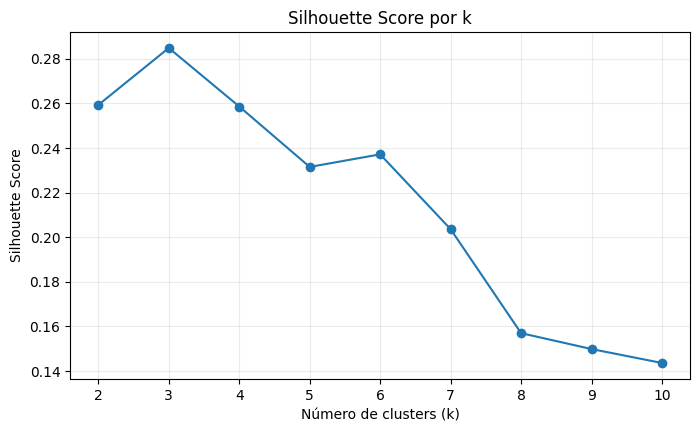

Melhor k pelo maior Silhouette Score: 3


In [9]:
resultados = []
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=20)
    rotulos = modelo.fit_predict(X_scaled)
    resultados.append({
        'k': k,
        'Inércia': modelo.inertia_,
        'Silhouette Score': silhouette_score(X_scaled, rotulos)
    })

metricas = pd.DataFrame(resultados)
display(metricas.round(4))

plt.figure(figsize=(8,4.5))
plt.plot(metricas['k'], metricas['Inércia'], marker='o')
plt.title('Método Elbow')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inércia')
plt.xticks(metricas['k'])
plt.grid(alpha=.25)
plt.show()

plt.figure(figsize=(8,4.5))
plt.plot(metricas['k'], metricas['Silhouette Score'], marker='o')
plt.title('Silhouette Score por k')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(metricas['k'])
plt.grid(alpha=.25)
plt.show()

melhor_k = int(metricas.loc[metricas['Silhouette Score'].idxmax(), 'k'])
print('Melhor k pelo maior Silhouette Score:', melhor_k)

# Interpretação: k=3 apresenta o maior Silhouette Score e também é coerente
# com a mudança de inclinação observada no gráfico do Elbow.

## 11. Ajuste final do K-means e análise dos grupos

In [10]:
kmeans = KMeans(n_clusters=melhor_k, random_state=42, n_init=20)
clusters = kmeans.fit_predict(X_scaled)
resultado = df.copy()
resultado['Cluster'] = clusters + 1

print('Quantidade de vinhos por grupo:')
display(resultado['Cluster'].value_counts().sort_index().to_frame('Quantidade'))

perfil = resultado.groupby('Cluster')[X.columns].mean()
display(perfil.round(3))

# Observação: os números dos clusters são rótulos arbitrários do K-means.
# O importante é comparar as médias das características de cada grupo.

Quantidade de vinhos por grupo:


,Quantidade
Cluster,
1,65
2,51
3,62


,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
Cluster,,,,,,,,,,,,,
1,12.251,1.897,2.231,20.063,92.738,2.248,2.050,0.358,1.624,2.973,1.063,2.803,510.169
2,13.134,3.307,2.418,21.241,98.667,1.684,0.819,0.452,1.146,7.235,0.692,1.697,619.059
3,13.677,1.998,2.466,17.463,107.968,2.848,3.003,0.292,1.922,5.454,1.065,3.163,1100.226


## 12. Visualização dos grupos com PCA

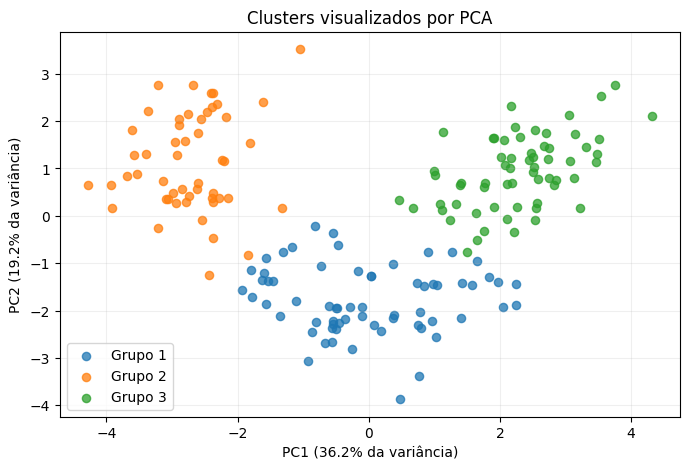

In [11]:
pca = PCA(n_components=2, random_state=42)
coord = pca.fit_transform(X_scaled)

plt.figure(figsize=(8,5))
for grupo in sorted(resultado['Cluster'].unique()):
    mascara = resultado['Cluster'].values == grupo
    plt.scatter(coord[mascara,0], coord[mascara,1], s=35, alpha=.75, label=f'Grupo {grupo}')
plt.title('Clusters visualizados por PCA')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% da variância)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% da variância)')
plt.legend()
plt.grid(alpha=.2)
plt.show()

## 13. Conclusões dos clusters

Com a configuração reproduzível usada neste notebook (`random_state=42`, `n_init=20`), os grupos podem ser caracterizados pelas médias:

- **Grupo 1:** menor teor alcoólico médio, menor intensidade de cor e menor Proline; perfil mais leve em várias medidas.
- **Grupo 2:** maior `Malic.acid`, maior intensidade de cor e menores valores médios de Hue e OD; considerando ácido málico como indicador de acidez, é o grupo mais ácido.
- **Grupo 3:** maior teor alcoólico médio, maior Proline e maiores médias de fenóis/flavanoides; também apresenta cinzas (`Ash`) relativamente mais altas.

Assim, os três clusters se diferenciam de forma interpretável por características químicas e de composição dos vinhos.

## Fontes

Dataset indicado no enunciado:
- Kaggle: https://www.kaggle.com/datasets/harrywang/wine-dataset-for-clustering
- GitHub Gist: https://gist.github.com/tijptjik/9408623
